# T02 — Layered soil

Real soil is rarely homogeneous. A two- or three-layer model, usually
inferred from a Wenner or Schlumberger sounding, captures the dominant
vertical variation of the resistivity and is enough for most
low-frequency grounding studies. This tutorial solves a ring earth
electrode in two- and three-layer soil and checks the results against
the homogeneous limits and against an independent evaluation of the
layered Green's function.

**You will learn**

- how to describe two- and multi-layer soil (`TwoLayerSoil`,
  `MultiLayerSoil`, `SoilLayer`);
- which backend solves which soil, and what happens when a backend
  cannot;
- how the layer thickness moves the impedance between two homogeneous
  limits;
- how electrodes that cross a layer interface are treated.

Runtime: a few seconds.

## The physics in three sentences

In a two-layer soil (upper layer $\rho_1$ of thickness $h_1$ over a
half-space $\rho_2$) the interface reflects part of the current
field. The reflection factor is

$$
K = \frac{\rho_2 - \rho_1}{\rho_2 + \rho_1}, \qquad -1 < K < 1,
$$

and the potential of a point current $I$ in the upper layer is the
infinite image series of Tagg (1964) and Sunde (1968): images at the
depths $\pm z' + 2nh_1$ with weights $K^n$,

$$
\varphi = \frac{\rho_1 I}{4\pi}\Bigl[\frac{1}{r_0} + \frac{1}{r_0'}
  + \sum_{n=1}^{\infty} K^n \Bigl(\frac{1}{r_n^+} + \frac{1}{r_n^-}
  + \frac{1}{r_n'^+} + \frac{1}{r_n'^-}\Bigr)\Bigr].
$$

For three or more layers no such simple series exists; the layered
Green's function is then a Sommerfeld integral over the radial
wavenumber, evaluated numerically.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf

print("groundfield", gf.__version__)


def ring_world(soil, *, radius=4.0, depth=0.8):
    # A buried ring earth electrode fed with 1 A from remote earth.
    world = gf.create_world(soil=soil)
    gf.create_electrode(
        world,
        "ring",
        name="ring",
        center=(0.0, 0.0, depth),
        radius=radius,
        wire_radius=0.005,
    )
    gf.create_source(world, attached_to="ring", magnitude=1.0)
    return world


def z_in(world, **engine_kwargs):
    # Input impedance at the first frequency of the engine, in Ohm.
    engine = gf.create_engine(**{"segment_length": 0.5, **engine_kwargs})
    return engine.solve(world).input_impedance()[0]

groundfield 2026.11.0


## A ring in two-layer soil

A 4 m ring at 0.8 m depth in a resistive topsoil
($\rho_1 = 300\ \Omega\,\mathrm m$, $h_1 = 3$ m) over a conductive
subsoil ($\rho_2 = 50\ \Omega\,\mathrm m$), so $K < 0$. With
`backend="image"` (the default) the engine forwards a two-layer soil to
the Tagg/Sunde backend `image_2layer`; the result records which backend
ran and how many image terms the series needed.

In [2]:
two_layer = gf.TwoLayerSoil(rho_1=300.0, rho_2=50.0, h_1=3.0)
K = (two_layer.rho_2 - two_layer.rho_1) / (two_layer.rho_2 + two_layer.rho_1)

result = gf.create_engine(segment_length=0.5).solve(ring_world(two_layer))
z_2layer = result.input_impedance()[0]
print(f"K = {K:+.3f}")
print(f"Z_in = {z_2layer.real:.4f} Ohm")
print(
    "backend requested / run:",
    result.metadata["backend"],
    "/",
    result.metadata["effective_backend"],
)
print("image series controls:", result.metadata["series"])

K = -0.714
Z_in = 16.0178 Ohm
backend requested / run: image / image_2layer
image series controls: {'max_terms': 300, 'tol': 1e-06, 'far_field': 'quadrupole'}


### Check 1: the homogeneous limit

With $\rho_2 = \rho_1$ the reflection factor vanishes, every image term
but the first two drops out, and the two-layer backend must reproduce
the homogeneous result exactly.

In [3]:
z_hom = z_in(ring_world(gf.HomogeneousSoil(rho=300.0)))
z_degenerate = z_in(ring_world(gf.TwoLayerSoil(rho_1=300.0, rho_2=300.0, h_1=3.0)))
print(f"homogeneous 300 Ohm m:        {z_hom.real:.12f} Ohm")
print(f"two-layer 300 / 300 Ohm m:    {z_degenerate.real:.12f} Ohm")

homogeneous 300 Ohm m:        22.288802670538 Ohm
two-layer 300 / 300 Ohm m:    22.288802670538 Ohm


In [4]:
assert z_degenerate == z_hom  # bit for bit

### Check 2: an independent evaluation of the layered Green's function

The `mom` backend evaluates the two-layer Green's function with the same
Tagg/Sunde series; `mom_sommerfeld` evaluates it as a Sommerfeld
integral by numerical quadrature. Both share one discretisation (pulse
basis, collocation at the segment midpoints), so any difference between
them is a difference in the Green's function itself.

The image backend uses a different current ansatz: one uniform leakage
current per straight wire and the exact line-source kernel. The difference
between `image` and the `mom` family is therefore a modelling
difference of the order of a percent for impedances, not an error of
the soil model. Tutorial
[T09](T09_choosing_an_engine_and_convergence.ipynb) discusses the
engines in detail.

In [5]:
z_mom = z_in(ring_world(two_layer), backend="mom")
z_sommerfeld = z_in(ring_world(two_layer), backend="mom_sommerfeld")
print(f"mom            (Tagg/Sunde series):     {z_mom.real:.9f} Ohm")
print(f"mom_sommerfeld (Sommerfeld quadrature): {z_sommerfeld.real:.9f} Ohm")
print(f"series vs quadrature:  {abs(z_mom / z_sommerfeld - 1):.1e}")
print(f"image vs mom:          {z_2layer.real / z_mom.real - 1:+.2%}")

mom            (Tagg/Sunde series):     15.810641564 Ohm
mom_sommerfeld (Sommerfeld quadrature): 15.810641509 Ohm
series vs quadrature:  3.4e-09
image vs mom:          +1.31%


In [6]:
assert abs(z_mom / z_sommerfeld - 1.0) < 1e-6
assert abs(z_2layer.real / z_mom.real - 1.0) < 0.03

## How the layer thickness moves the impedance

For a very thin top layer the ring sits in the lower layer and sees
(almost) only $\rho_2$; for a very thick one it sees only $\rho_1$. In
between, the impedance moves smoothly from one homogeneous limit to the
other. We sweep $h_1$ over four decades for both contrasts —
resistive over conductive ($K < 0$) and conductive over resistive
($K > 0$). Thicknesses for which the interface lies closer to the ring
than two segment lengths are skipped: there the engine warns that the
discretisation should be refined. Note how slowly a *conductive* top
layer disappears: even a few centimetres of it spread the current
sideways, and the deviation from the $\rho_2$ limit shrinks only in
proportion to $h_1$.

300 over 50 Ohm m (K < 0): h_1 = 0.005 m -> 3.716 Ohm (rho_2 limit 3.715), h_1 = 1000 m -> 22.263 Ohm (rho_1 limit 22.289)
50 over 300 Ohm m (K > 0): h_1 = 0.005 m -> 22.229 Ohm (rho_2 limit 22.289), h_1 = 1000 m -> 3.725 Ohm (rho_1 limit 3.715)


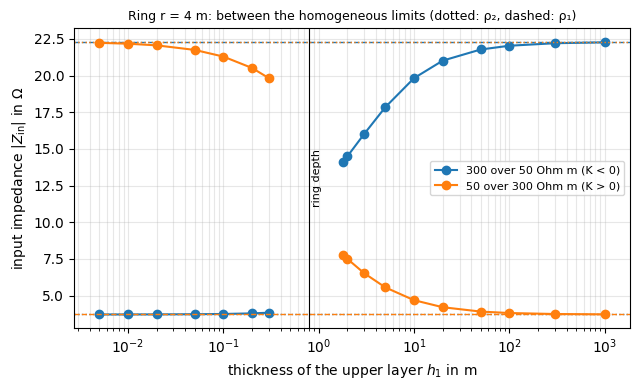

In [7]:
h_values = np.array(
    [
        0.005,
        0.01,
        0.02,
        0.05,
        0.1,
        0.2,
        0.3,
        1.8,
        2.0,
        3.0,
        5.0,
        10.0,
        20.0,
        50.0,
        100.0,
        300.0,
        1000.0,
    ]
)
contrasts = {
    "300 over 50 Ohm m (K < 0)": (300.0, 50.0),
    "50 over 300 Ohm m (K > 0)": (50.0, 300.0),
}

sweep = {}
for label, (rho_1, rho_2) in contrasts.items():
    values = [
        z_in(ring_world(gf.TwoLayerSoil(rho_1=rho_1, rho_2=rho_2, h_1=h))).real
        for h in h_values
    ]
    limits = (
        z_in(ring_world(gf.HomogeneousSoil(rho=rho_2))).real,  # h_1 -> 0
        z_in(ring_world(gf.HomogeneousSoil(rho=rho_1))).real,  # h_1 -> infinity
    )
    sweep[label] = (np.array(values), limits)

fig, ax = plt.subplots(figsize=(6.5, 4.0))
below = h_values < 0.8  # the ring lies in the lower layer
for k, (label, (values, (z_low, z_high))) in enumerate(sweep.items()):
    ax.semilogx(h_values[below], values[below], "o-", color=f"C{k}", label=label)
    ax.semilogx(h_values[~below], values[~below], "o-", color=f"C{k}")
    ax.axhline(z_low, color=f"C{k}", ls=":", lw=1)
    ax.axhline(z_high, color=f"C{k}", ls="--", lw=1)
ax.axvline(0.8, color="k", lw=0.8)
ax.text(
    0.85,
    0.5,
    "ring depth",
    rotation=90,
    va="center",
    fontsize=8,
    transform=ax.get_xaxis_transform(),
)
ax.set_xlabel("thickness of the upper layer $h_1$ in m")
ax.set_ylabel(r"input impedance $|Z_\mathrm{in}|$ in $\Omega$")
ax.set_title(
    "Ring r = 4 m: between the homogeneous limits (dotted: ρ₂, dashed: ρ₁)", fontsize=9
)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

for label, (values, (z_low, z_high)) in sweep.items():
    print(
        f"{label}: h_1 = 0.005 m -> {values[0]:.3f} Ohm (rho_2 limit {z_low:.3f}), "
        f"h_1 = 1000 m -> {values[-1]:.3f} Ohm (rho_1 limit {z_high:.3f})"
    )

In [8]:
for values, (z_low, z_high) in sweep.values():
    assert abs(values[0] / z_low - 1.0) < 0.005  # thin top layer: rho_2
    assert abs(values[-1] / z_high - 1.0) < 0.005  # thick top layer: rho_1
    steps = np.diff(values)
    assert np.all(steps < 0) if z_high < z_low else np.all(steps > 0)  # monotonic

## Electrodes that cross the interface

A driven rod often reaches through the top layer into the subsoil. The
current density on such a rod is not uniform: much more current leaves
the part in the conductive layer. The image backend gives an electrode
that crosses $h_1$ one uniform-current *owner* per layer, all at the
same potential. That is exactly the same as building the rod from two
bonded pieces by hand, which shows how the current divides:

In [9]:
def rod_world(soil, *, split):
    world = gf.create_world(soil=soil)
    if split:  # two bonded rods: 0.5 ... 3.0 m and 3.0 ... 6.5 m
        gf.create_electrode(
            world,
            "rod",
            name="rod",
            position=(0, 0, 0.5),
            length=2.5,
            wire_radius=0.008,
        )
        gf.create_electrode(
            world,
            "rod",
            name="rod_low",
            position=(0, 0, 3.0),
            length=3.5,
            wire_radius=0.008,
        )
        gf.create_conductor(
            world, name="bond", start="rod", end="rod_low"
        )  # ideal bond
    else:  # one rod 0.5 ... 6.5 m through h_1 = 3 m
        gf.create_electrode(
            world,
            "rod",
            name="rod",
            position=(0, 0, 0.5),
            length=6.0,
            wire_radius=0.008,
        )
    gf.create_source(world, attached_to="rod", magnitude=1.0)
    return world


engine = gf.create_engine(segment_length=0.25)
one_rod = engine.solve(rod_world(two_layer, split=False))
two_rods = engine.solve(rod_world(two_layer, split=True))
z_mom_rod = gf.create_engine(backend="mom", segment_length=0.25).solve(
    rod_world(two_layer, split=False)
)

print(f"one rod through h_1:      Z_in = {one_rod.input_impedance()[0].real:.6f} Ohm")
print(f"two bonded rods:          Z_in = {two_rods.input_impedance()[0].real:.6f} Ohm")
print(f"mom, one rod:             Z_in = {z_mom_rod.input_impedance()[0].real:.6f} Ohm")
share = two_rods.electrode_currents["rod_low"][0].real
print(
    f"current leaving the part below h_1: {share:.1%} on {3.5 / 6.0:.0%} of the length"
)

one rod through h_1:      Z_in = 13.289435 Ohm
two bonded rods:          Z_in = 13.289435 Ohm
mom, one rod:             Z_in = 13.040331 Ohm
current leaving the part below h_1: 89.7% on 58% of the length


In [10]:
z_one, z_two = one_rod.input_impedance()[0], two_rods.input_impedance()[0]
assert abs(z_one / z_two - 1.0) < 1e-12
assert abs(z_one.real / z_mom_rod.input_impedance()[0].real - 1.0) < 0.03
assert share > 0.8

## Three and more layers

A `MultiLayerSoil` is a list of `SoilLayer` entries from the top down;
every layer has a resistivity `rho` and a thickness `h`, the last one
is the half-space (`h=None`, the default). The image family covers one
and two *distinct* layers: adjacent layers of equal resistivity are
merged first, so the stack below is the two-layer soil from above in
disguise and gives the identical result.

In [11]:
disguised = gf.MultiLayerSoil(
    layers=[
        gf.SoilLayer(rho=300.0, h=3.0),
        gf.SoilLayer(rho=50.0, h=5.0),
        gf.SoilLayer(rho=50.0),
    ]
)
z_disguised = z_in(ring_world(disguised))
print(f"three declared layers, two distinct: {z_disguised.real:.12f} Ohm")
print(f"two-layer soil:                      {z_2layer.real:.12f} Ohm")

three declared layers, two distinct: 16.017783091230 Ohm
two-layer soil:                      16.017783091230 Ohm


In [12]:
assert z_disguised == z_2layer

With three distinct layers the image family has no series to sum. The
engine checks this *before* solving and raises a
`BackendCapabilityError` that names the backends that can solve the
world:

In [13]:
three_layer = gf.MultiLayerSoil(
    layers=[
        gf.SoilLayer(rho=300.0, h=3.0),
        gf.SoilLayer(rho=50.0, h=5.0),
        gf.SoilLayer(rho=500.0),
    ]
)
try:
    z_in(ring_world(three_layer), backend="image")
except gf.BackendCapabilityError as exc:
    print("BackendCapabilityError:", exc)

BackendCapabilityError: Backend 'image' (running 'image_nlayer') cannot solve this world: it does not support 3-layer soil. Backends that can: 'mom_sommerfeld', 'fem' (experimental).


`mom_sommerfeld` evaluates the layered Green's function by Sommerfeld
quadrature and has no layer limit. As a consistency check we vary the
resistivity $\rho_3$ of the bottom half-space: at $\rho_3 = \rho_2$ the
result must coincide with the two-layer `mom_sommerfeld` value from
above, and it must change smoothly and monotonically around it.

In [14]:
rho_3_values = [10.0, 25.0, 50.0, 100.0, 500.0, 2000.0]
z_three = []
for rho_3 in rho_3_values:
    soil = gf.MultiLayerSoil(
        layers=[
            gf.SoilLayer(rho=300.0, h=3.0),
            gf.SoilLayer(rho=50.0, h=5.0),
            gf.SoilLayer(rho=rho_3),
        ]
    )
    z_three.append(z_in(ring_world(soil), backend="mom_sommerfeld").real)
    print(f"rho_3 = {rho_3:6.0f} Ohm m: Z_in = {z_three[-1]:.4f} Ohm")
print(f"two-layer mom_sommerfeld:  Z_in = {z_sommerfeld.real:.4f} Ohm")

rho_3 =     10 Ohm m: Z_in = 15.2122 Ohm
rho_3 =     25 Ohm m: Z_in = 15.4680 Ohm
rho_3 =     50 Ohm m: Z_in = 15.8106 Ohm
rho_3 =    100 Ohm m: Z_in = 16.3148 Ohm
rho_3 =    500 Ohm m: Z_in = 18.0489 Ohm
rho_3 =   2000 Ohm m: Z_in = 19.9025 Ohm
two-layer mom_sommerfeld:  Z_in = 15.8106 Ohm


In [15]:
assert abs(z_three[rho_3_values.index(50.0)] / z_sommerfeld.real - 1.0) < 1e-9
assert np.all(np.diff(z_three) > 0)

## Summary

| Soil | Classes | Backends |
|---|---|---|
| homogeneous | `HomogeneousSoil` | `image`, `mom`, `mom_sommerfeld`, `fem` (experimental) |
| two layers | `TwoLayerSoil`, or a `MultiLayerSoil` with two distinct layers | `image` (forwards to `image_2layer`), `mom`, `mom_sommerfeld` |
| three or more distinct layers | `MultiLayerSoil` | `mom_sommerfeld`, `fem` (experimental) |

- The homogeneous limits ($\rho_2 = \rho_1$, very thin or very thick top
  layer) are cheap and strong checks of any layered model.
- `mom` and `mom_sommerfeld` share the discretisation and differ in how
  the layered Green's function is evaluated; their agreement checks the
  soil model.
- Electrodes through an interface carry one uniform current per layer.

**Next:** [T03 — interconnected systems and the three
impedances](T03_interconnected_systems_and_impedances.ipynb).